# 01 — Projeto: pergunta, escopo, pessoas, estado atual e glossário

Atualiza `Relatórios do Projeto/01_PROJETO.md` (estado de outubro/2026). Tudo o que é preciso saber sobre o
projeto antes de olhar para os dados (notebook 02) e para o método (notebook 03).

## O que mudou desde o relatório de outubro

| Tema | Relatório 01 (14/10/2026) | Agora (10/11/2026) | Registro |
|---|---|---|---|
| Pergunta | estimar a taxa de abandono em *t*+1 | identificar **qual informação** carrega sinal sobre o abandono em *t*+1; a previsão é o instrumento | `DECISOES.md` 2026-11-02; validação do orientador pendente |
| Base do orientador | "ausente no clone local; pedir ao orientador" | presente em `dados/externo/` (6 arquivos no manifesto), **regerada por código** e comparada: mesmas 6.054 linhas | `DECISOES.md` 2026-09-30; notebook 02 |
| Bootstrap | ~3h52 (pasta sincronizada na nuvem) | **36 min** num clone limpo, com os Parquets idênticos byte a byte | síntese §1.1 |
| Série histórica | 2019–2025 | 2019–2025 na base oficial; **2007–2025** de rendimento e infraestrutura no `gustavo/` | notebook 02 |
| Experimentos | notebooks v1/v1_old (R² 0,16 a 0,20) | substituídos por um protocolo pré-especificado (`gustavo/avaliacao/`); os R² antigos ficam como [PONTUAL] | síntese §3.4 e §6.2 |
| "TDI é a variável mais importante" | achado principal | [REFUTADO] na forma geral (a evidência usava o trio contábil). Sobrevive restrito: **a árvore depende do TDI**, separável do rendimento e do ATU | síntese §3.2 e §4 #11 |
| Enriquecimento (Fase 3) | próxima fase | **suspenso** enquanto o instrumento não separar nada; a infraestrutura (Gustavo) foi testada e não teve sinal | `DECISOES.md` 2026-11-02 |

In [1]:
import sys
from pathlib import Path

AQUI = Path.cwd()                                  # o notebook roda de Dados-do-Projeto/Contexto do Projeto
if not (AQUI / "gerar_tabelas.py").exists():
    raise FileNotFoundError(f"Abra este notebook de dentro de Dados-do-Projeto/Contexto do Projeto (pasta atual: {AQUI})")
DADOS_DO_PROJETO = AQUI.parent
OFICIAL = DADOS_DO_PROJETO / "abandono-escolar"    # junction para Pmonkey/abandono-escolar
GUSTAVO = DADOS_DO_PROJETO / "gustavo"
sys.path.insert(0, str(OFICIAL))
sys.path.insert(0, str(AQUI))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

import desenho as D
from src import figuras as F

print(F.conferir_ambiente(OFICIAL / "requirements.txt"))
F.aplicar_estilo()
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 30)
TABELAS = AQUI / "tabelas"                         # python gerar_tabelas.py
FIGURAS = AQUI / "figuras"


def figura_existente(caminho, largura=820):
    """Mostra uma figura gerada por outro notebook (não a recalcula)."""
    F.exigir({caminho.name: caminho}, como_gerar="executar o notebook que a gera (ver a legenda)")
    display(Image(filename=str(caminho), width=largura))

{'pandas': '3.0.5', 'numpy': '2.5.3', 'matplotlib': '3.11.1'}


In [2]:
ENTRADAS = {
    "familias": TABELAS / "familias_holm.csv",           # gerar_tabelas.py, a partir de gustavo/saida/avaliacao/02d_testes.csv
    "universo": TABELAS / "universo_por_ano.csv",        # gerar_tabelas.py
    "desfecho_ano": GUSTAVO / "saida" / "relatorios" / "desfecho_por_ano.csv",   # gustavo/analises/05_descritivo_por_ano.py
    "sintese": GUSTAVO / "saida" / "avaliacao" / "sintese_numeros.csv",          # gustavo/avaliacao/sintese_numeros.py
}
F.exigir(ENTRADAS, como_gerar='python "Contexto do Projeto/gerar_tabelas.py"; os do gustavo/ pelo script indicado')
familias = pd.read_csv(ENTRADAS["familias"])
universo = pd.read_csv(ENTRADAS["universo"])
desfecho_ano = pd.read_csv(ENTRADAS["desfecho_ano"])
sintese = pd.read_csv(ENTRADAS["sintese"])

# Parte A — Identificação e pergunta

## 1. Identificação

- **Título:** Risco de abandono escolar em Roraima.
- **Tipo:** iniciação científica (PIBIC/UERR, Edital 35/2026) **e** artigo da disciplina de Mineração de Dados.
- **Orientador:** Prof. Bruno Cesar Barreto Figueiredo · **Instituição:** Universidade Estadual de Roraima (UERR).
- **Repositórios:**
  - `abandono-escolar` (oficial; github.com/gabsma25/abandonoescolar);
  - `Dados-do-Projeto` (pipeline estendido do Gustavo, avaliação e estes notebooks).
  - Branch de trabalho nos dois: `avaliacao-etapas-1-2`.
- **Status em novembro/2026:**
  - os dois pipelines de dados e o instrumento de avaliação rodam de ponta a ponta, com testes verdes;
  - a Etapa 2 terminou com um resultado claro: o instrumento, como está, não tem poder para separar os blocos
    de informação (notebook 03);
  - a validação, pelo orientador, das regras de 02/11 e da mudança de objetivo está pendente.

## 2. Pergunta de pesquisa

**Antes (até 02/11/2026; relatório 01 de outubro):**

> Com os indicadores educacionais de uma escola de Roraima no ano *t*, é possível estimar a taxa de abandono
> esperada no ano *t*+1, nos anos finais do ensino fundamental e no ensino médio, para apoiar ações
> preventivas de gestão?

**Agora (`abandono-escolar/CLAUDE.md` §1, reescrito em 03/11/2026):**

> Identificar qual informação sobre uma escola no ano *t* carrega sinal sobre o abandono em *t*+1, por etapa
> (AF e EM). A previsão é o instrumento: Recall@K contra baselines pré-especificados, com intervalo e correção
> de Holm.

**Por que mudou.** Ter o abandono de *t* entre os preditores dá uma resposta circular: o que prevê abandono é
o abandono. Perguntar *qual bloco acrescenta* (rendimento defasado, TDI, ATU, esforço docente,
infraestrutura) leva a algo útil para a gestão. Também obriga a comparar com a persistência e a medir a
incerteza. A troca foi aplicada sem consultar o orientador, como o §6 exige; está registrada como falha de
processo (`DECISOES.md`, 2026-11-02).

## 3. Escopo

**O que o projeto faz:**

- unidade **escola-ano** (D1), escolas **públicas** de Roraima com taxa de rendimento na etapa (D3);
- **dois painéis**, anos finais do EF e ensino médio, cada modelo só com variáveis da sua etapa (D2; doc 06 D15);
- desfecho: **taxa de abandono da etapa em *t*+1** (D4); desfechos binários (`OCORRE_*`, `ALTO_*`) são
  auxiliares, e o limiar de "alto" não foi decidido;
- dados **públicos** do INEP: Indicadores Educacionais e Censo Escolar.

**O que o projeto não faz:**

- **não prevê aluno:** a base é agregada por escola;
- **não trata de evasão:** abandono é sair durante o ano letivo e existe por escola; evasão é não se
  matricular no ano seguinte e só é publicada de forma agregada;
- **não ranqueia nem pune escolas:** prioriza para diagnóstico;
- **não é causal:** "o modelo depende do TDI" não quer dizer "o TDI causa abandono";
- **não escolhe variável pela correlação com o desfecho** (regra 3);
- **no protocolo de avaliação, não avalia modelo na transição 2024→2025**, que é o teste bloqueado (D7).
  Antes do protocolo, os notebooks de outubro (smoke test, v1_old, v1 e v1_corrigido) já tinham testado
  modelos nela; o notebook 04 detalha esse histórico.

## 4. Justificativa

- O abandono é crítico em Roraima, com escolas indígenas, rurais, ribeirinhas e em assentamentos, cada uma com
  dinâmica própria.
- O Estado precisa priorizar: não há equipe para acompanhar todas as escolas.
- Saber *que tipo de informação* antecipa o abandono diz o que vale a pena coletar e acompanhar. O
  instrumento mostra também quando a informação não acrescenta nada à persistência.
- A comparação AF × EM diante do Pé-de-Meia (só EM, desde 2024) foi motivação do desenho original. A variável
  nunca foi construída (síntese §5.5).

## 5. Produtos e base ética

| Produto | Estado |
|---|---|
| Relatório PIBIC · artigo da disciplina | pendentes |
| Repositório com aquisição, manifesto e base reproduzível | feito (`abandono-escolar`) |
| Base estendida 2007–2025 + infraestrutura | feita (`gustavo/`); 2007–2018 não reverificável nesta máquina |
| Instrumento de avaliação com testes | feito (`gustavo/avaliacao/`, teste 04: 65 checks) |
| Notebooks que exibem os resultados | `abandono-escolar/notebooks/01–03` e esta pasta |
| Síntese com níveis de evidência | `abandono-escolar/docs/SINTESE_DO_PROJETO.md` |

**Base ética:** dados públicos do INEP (Lei de Acesso à Informação); nenhum dado pessoal; unidade agregada
(escola); uso explicitamente não punitivo.

## 6. Delimitações temporais

Cada fonte cobre um período diferente. O painel da avaliação só usa os anos em que todas existem. A figura
lê as contagens por ano: um ano sem escolas com o dado aparece vazio, nunca com zero.

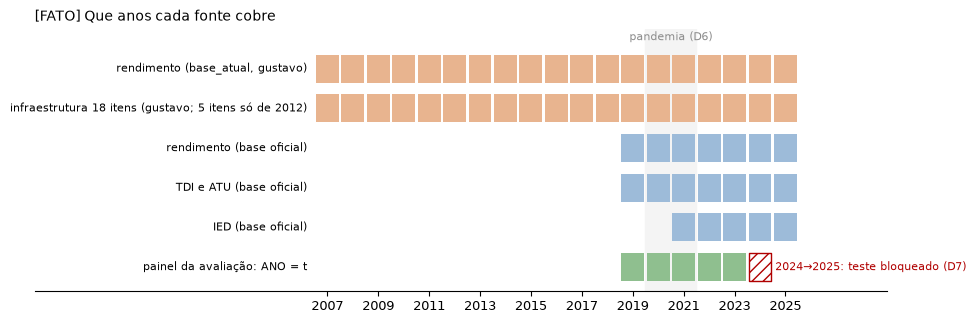

In [3]:
u = universo[universo["ANO"] != "total"].astype({"ANO": int}).set_index("ANO")
anos_atual = sorted(desfecho_ano["ano"].unique())
faixas = [
    ("rendimento (base_atual, gustavo)", anos_atual, "gustavo"),
    ("infraestrutura 18 itens (gustavo; 5 itens só de 2012)", anos_atual, "gustavo"),
    ("rendimento (base oficial)", list(u.index[u["com_REND"] > 0]), "oficial"),
    ("TDI e ATU (base oficial)", list(u.index[(u["com_TDI"] > 0) & (u["com_ATU"] > 0)]), "oficial"),
    ("IED (base oficial)", list(u.index[u["com_IED"] > 0]), "oficial"),
    ("painel da avaliação: ANO = t", list(range(2019, 2025)), "avaliacao"),
]
cores = {"gustavo": "#e8b48f", "oficial": "#9dbbd9", "avaliacao": "#8fbf8f"}
fig, ax = plt.subplots(figsize=(11, 3.4))
for i, (rotulo, anos, tipo) in enumerate(faixas[::-1]):
    ax.broken_barh([(a - 0.45, 0.9) for a in anos], (i - 0.35, 0.7), facecolors=cores[tipo])
    ax.text(2006.2, i, rotulo, ha="right", va="center", fontsize=8)
ax.broken_barh([(2024 - 0.45, 0.9)], (-0.35 + 0, 0.7), facecolors="white", edgecolors=D.VERMELHO, hatch="///")
ax.text(2024.6, 0, "2024→2025: teste bloqueado (D7)", va="center", fontsize=8, color=D.VERMELHO)
ax.axvspan(2019.5, 2021.5, color="#f4f4f4", zorder=0)
ax.text(2020.5, len(faixas) - 0.35, "pandemia (D6)", ha="center", va="bottom", fontsize=8, color=D.CINZA)
ax.set_yticks([])
ax.set_xlim(1995.5, 2029)
ax.set_ylim(-0.6, len(faixas))
ax.set_xticks(range(2007, 2026, 2))
ax.spines["left"].set_visible(False)
F.titulo(ax, "Que anos cada fonte cobre", "FATO")
F.salvar(fig, FIGURAS, "01_cobertura_temporal")
plt.show()

O abandono de *t* vem da segunda etapa do Censo, coletada no ano seguinte, e é publicado pelo INEP **durante
*t*+1**: a planilha de 2025 já estava no projeto em 09/09/2026, data do download no `MANIFEST.csv`. Quem
prioriza escolas no **início** de *t*+1 ainda não a tem; tem o abandono de *t*−1. Esse atraso explica o
Cenário B e o baseline B1R_lag (notebook 03).

O `DECISOES.md` (entrada do B1R_lag, 02/11) diz que o abandono de *t* "só é publicado depois do fim de
*t*+1". O manifesto mostra que não. A conclusão continua válida para a decisão no início do ano letivo, mas
a frase precisa de correção, que cabe à pesquisadora (notebook 06, §5).

# Parte B — Pessoas

| Pessoa | Papel | Contribuição registrada |
|---|---|---|
| **Prof. Bruno Cesar Barreto Figueiredo** | orientador | proposta detalhada; base longitudinal v1.0 (17/09/2026); decisões D1–D7 e D10; avaliação do ritmo em 30/09 |
| **Gabriela Monteiro** | integrante (pesquisadora) | repositório oficial e procedência; regeração da base; protocolo de avaliação, Etapas 1 e 2 (02/11); análises 03–05 e testes 04–07 do `gustavo/`; notebooks |
| **Gustavo** | integrante | pipeline estendido `gustavo/` (07–14/10/2026): rendimento 2007–2025 em 3 layouts, 18 itens de infraestrutura, regra de fonte do Censo, índices `zano` e IIE; testes 01–03; relatórios 01–05 |
| **João Ricardo** | integrante | repositório próprio (`ricardo/abandonoEscolar`), consultado só para leitura |

O trabalho é distribuído conforme a fase, sem hierarquia fixa. O orientador acompanha e dá retorno sobre
decisões metodológicas: o que muda o que a pesquisa afirma volta para ele (`CLAUDE.md` §6).

# Parte C — Estado atual

## 7. Concluído

- **Procedência e base oficial:**
  - 110 zips do INEP no manifesto com sha256 (103 de indicadores, 7 do Censo);
  - base de 6.054 × 59 regerada e comparada com a v1.0;
  - bootstrap reproduzido em 36 min;
  - 70 testes pytest.
- **Base estendida:** 12.597 × 55, 2007–2025, com infraestrutura, e 7 relatórios de checks (notebook 00, §3.1).
- **Etapa 1 (baselines, 2009–2025):** a persistência ordena melhor que o acaso em quase todas as transições.
  Como valor previsto, porém, perde para a média.
- **Etapa 2 (walk-forward 2021–2024, Cenário B):** quatro blocos, dois modelos, bootstrap por escola e Holm
  em 152 testes de 5 famílias declaradas antes de rodar.

## 8. Resultados em uma figura

Cada família é uma pergunta declarada antes de rodar. A barra cinza conta os testes da família. A barra azul
conta os que sobrevivem à correção de Holm, e só eles valem como achado [MEDIDO].

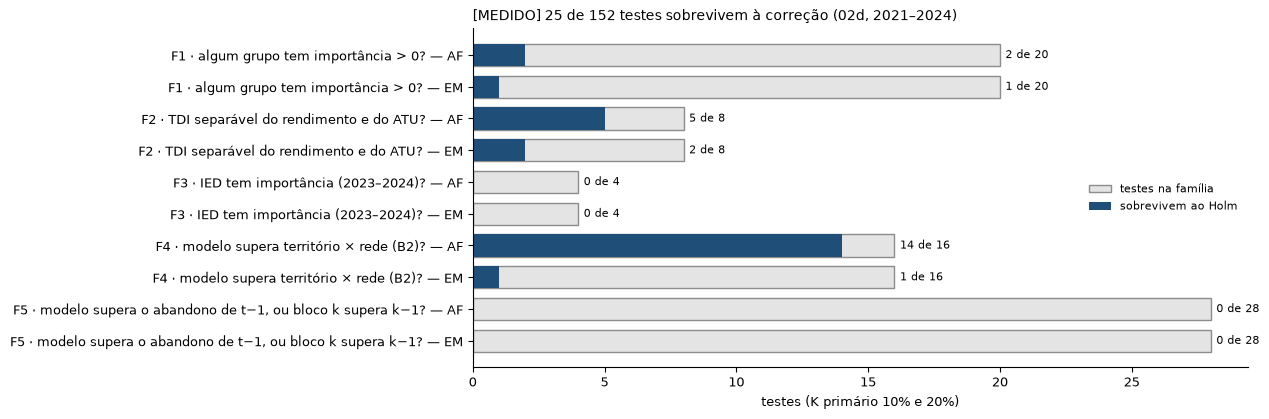

In [4]:
perguntas = {
    "F1": "F1 · algum grupo tem importância > 0?",
    "F2": "F2 · TDI separável do rendimento e do ATU?",
    "F3": "F3 · IED tem importância (2023–2024)?",
    "F4": "F4 · modelo supera território × rede (B2)?",
    "F5": "F5 · modelo supera o abandono de t−1, ou bloco k supera k−1?",
}
f = familias.assign(rotulo=familias["familia"].map(perguntas) + " — " + familias["etapa"])[::-1]
fig, ax = plt.subplots(figsize=(10, 4.4))
y = range(len(f))
ax.barh(y, f["testes"], color="#e4e4e4", edgecolor=D.CINZA, height=0.7, label="testes na família")
ax.barh(y, f["sobrevivem"], color=D.AZUL, height=0.7, label="sobrevivem ao Holm")
for yi, (n, s) in enumerate(zip(f["testes"], f["sobrevivem"])):
    ax.annotate(f"{s} de {n}", (n, yi), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
ax.set_yticks(list(y), f["rotulo"])
ax.set_xlabel("testes (K primário 10% e 20%)")
ax.legend(loc="center right", fontsize=8)
F.titulo(ax, f"{f['sobrevivem'].sum()} de {f['testes'].sum()} testes sobrevivem à correção (02d, 2021–2024)", "MEDIDO")
F.salvar(fig, FIGURAS, "01_familias_holm")
plt.show()

**Leitura** (síntese §3; detalhe no notebook 03 e em `abandono-escolar/notebooks/03_avaliacao`):

1. **[MEDIDO] Nos anos finais, a informação da própria escola ordena melhor do que território e rede:** os 8
   modelos superam o B2 em ao menos um K (F4-AF: 14 de 16). No EM, 1 de 16.
2. **[MEDIDO] A árvore depende do TDI**, de forma separável do rendimento e do ATU, nas duas etapas (F1 e F2).
3. **[MEDIDO, nulo] Nenhum modelo supera ordenar as escolas pelo abandono de *t*−1, e nenhum bloco supera o
   anterior** (F5: 0 de 56). Com 4 transições de teste e cerca de 160 a 240 escolas por ano, o intervalo de
   Recall@10% de um ano tem largura ~0,30: tão largo quanto a variação dos próprios dados [FATO].
4. **Infraestrutura:** 0 de 8 testes na F1. Ela "falha por ser medida do prédio, não por ser permanente": o
   IIE é tão persistente quanto o TDI (+0,98 contra +0,88). Sai do modelo e fica na pesquisa, como
   estratificação para a equidade.
5. **IED:** 0 de 8 na F3. É ausência de evidência, não evidência de ausência: só há dois anos de teste com
   IED no treino.

## 9. Pendências

| Pendência | Tipo | Onde |
|---|---|---|
| Validação pelo orientador da mudança de objetivo e das regras de 02/11 (Cenário B, B1R_lag, Holm, K) | processo | `DECISOES.md` |
| D8: escola indígena, localização diferenciada, matrículas AF/EM (equidade e peso) | decisão do orientador | metodologia §4.7 |
| D9: ATU total + multisseriada · P017: tirar escolas só de infantil · oferta de EM 2025 (P001) | decisão | `problemas.csv` |
| D11: estender a série oficial a 2007–2018 | decisão + download | metodologia §10 |
| Sensibilidade S1–S4 (D6), equidade por estrato, limiar `ALTO_*`, B4 | nunca rodados | síntese §5.5 |
| Linhas P006, P019–P023 e P027 propostas para o `problemas.csv` | colar à mão (pesquisadora) | síntese, fim |
| Relatório PIBIC e artigo | produto | — |

# Parte D — Glossário

## Siglas do INEP

| Sigla | Nome | O que é no projeto |
|---|---|---|
| **Censo Escolar** | Censo Escolar da Educação Básica | microdados anuais por escola: oferta, infraestrutura, localização diferenciada, matrículas; no projeto, os 18 itens de infraestrutura e as propostas D8 |
| **tx_rend** | Taxas de Rendimento Escolar | aprovação, reprovação e abandono por escola e etapa; aprovação + reprovação + abandono = 100 (P026). Fonte do desfecho |
| **TDI** | Taxa de Distorção Idade-Série | % de alunos com idade ≥ a recomendada + 2 anos; mede trajetória acumulada. Preditor (D5) |
| **ATU** | Média de Alunos por Turma | matrículas ÷ turmas; turmas multisseriadas ficam fora da média por série (P016), e por isso o `ATU_FUN_AF` falta em 71% das públicas |
| **IED** | Indicador de Esforço Docente | % de professores em cada nível de 1 a 6 (escolas, turnos, alunos, etapas); os 6 somam 100 e `ALTO` = N4+N5+N6. Só desde 2021 na base |
| **HAD** | Média de Horas-Aula Diárias | baixado (2019–2025), nunca usado (P019) |
| **INSE** | Indicador de Nível Socioeconômico | depende do Saeb; nunca carregado; só serviria para comparar grupos |
| **Pé-de-Meia** | programa federal (2024–) | permanência no EM público; não construído como variável |

## Termos do projeto

| Termo | Definição |
|---|---|
| **Escola-ano** | uma linha = uma escola num ano; chave `ANO + CO_ENTIDADE` |
| **AF / EM** | anos finais do EF (6º ao 9º) / ensino médio; um painel e um modelo para cada (D2) |
| **t → t+1** | preditores do ano *t*; desfecho `*_T1` do ano *t*+1. `ANO_ALVO` = *t*+1 **se a escola existe em *t*+1**; senão, vazio |
| **`_LAG1` · `_DELTA1` · `_T1`** | valor de *t*−1 · variação *t* − (*t*−1) · desfecho de *t*+1 (só desfecho, nunca preditor) |
| **Universo** | base oficial: união das chaves das 4 planilhas de indicadores (6.054 linhas). Avaliação: públicas com alvo em *t*+1 (notebook 02) |
| **Ausência estrutural** | falta porque a escola não tem a etapa ou a fonte não existia no ano; nunca vira 0 (regra 5) |
| **Falta de resposta** | o dado deveria existir e não veio; tratada diferente da ausência estrutural |
| **`DISP_*`** | 1 se a escola tem ao menos um valor daquela fonte no ano; controle de ausência, não preditor |
| **Cenário A / B** | A: com o rendimento de *t* (teto otimista). **B (principal):** sem ele, só com o que existe na hora de decidir |
| **Bloco** | conjunto de colunas que entra ou sai junto: 1 rendimento defasado; 2 +TDI/ATU; 3 +IED; 4 +infraestrutura |
| **Variação defasada** | abandono(*t*−1) − abandono(*t*−2); o `DELTA1` da base reconstrói o abandono de *t* e anularia o Cenário B |
| **Baselines** | B0 média; B1 persistência; B1R ordenar pelo abandono de *t* (oráculo); **B1R_lag** ordenar pelo de *t*−1 (barra principal); B2 mediana por localização × dependência |
| **Recall@K** | das K escolas de maior abandono real em *t*+1, quantas a ordenação põe entre as suas K primeiras; K = 10% e 20% das escolas do ano |
| **Walk-forward** | treina com as transições anteriores e testa na seguinte, ano a ano (janela expansiva) |
| **Bootstrap por escola** | reamostra escolas, não linhas, para o intervalo respeitar que a mesma escola aparece em vários anos |
| **Família e Holm** | conjunto de testes de uma pergunta declarada antes; Holm controla o erro do conjunto |
| **Importância por permutação de grupo** | queda de Recall@K ao embaralhar um grupo de colunas inteiro; mede o que o modelo **usa**, não causa |
| **Níveis de evidência** | FATO, MEDIDO, PONTUAL, EXPLORATÓRIO, INTERPRETAÇÃO, REFUTADO (notebook 00) |
| **Teste bloqueado** | 2024→2025: uma única avaliação, depois de congelar tudo (D7). O protocolo nunca o usou, mas os notebooks de outubro testaram modelos nele e o desfecho de 2025 aparece em 5 análises descritivas (notebook 04) |
| **Abandono × evasão** | abandono: sai durante o ano (por escola). Evasão: não se matricula no ano seguinte (agregada). O projeto trata de abandono |
| **Explicabilidade × causalidade** | o modelo usar uma variável é associação, não causa |